In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/Users/partha/AI_ML_Projects/Heart-Disease-Prediction-ML/datasets/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df.shape

(303, 14)

In [5]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [6]:
df.isnull().any()

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
exang       False
oldpeak     False
slope       False
ca          False
thal        False
target      False
dtype: bool

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Visualization of the data

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

/var/folders/_k/tz1g6g6j10v_wxt_5fvf1zhh0000gn/T/ipykernel_2392/323989216.py:4: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  g = df.hist(ax=ax)


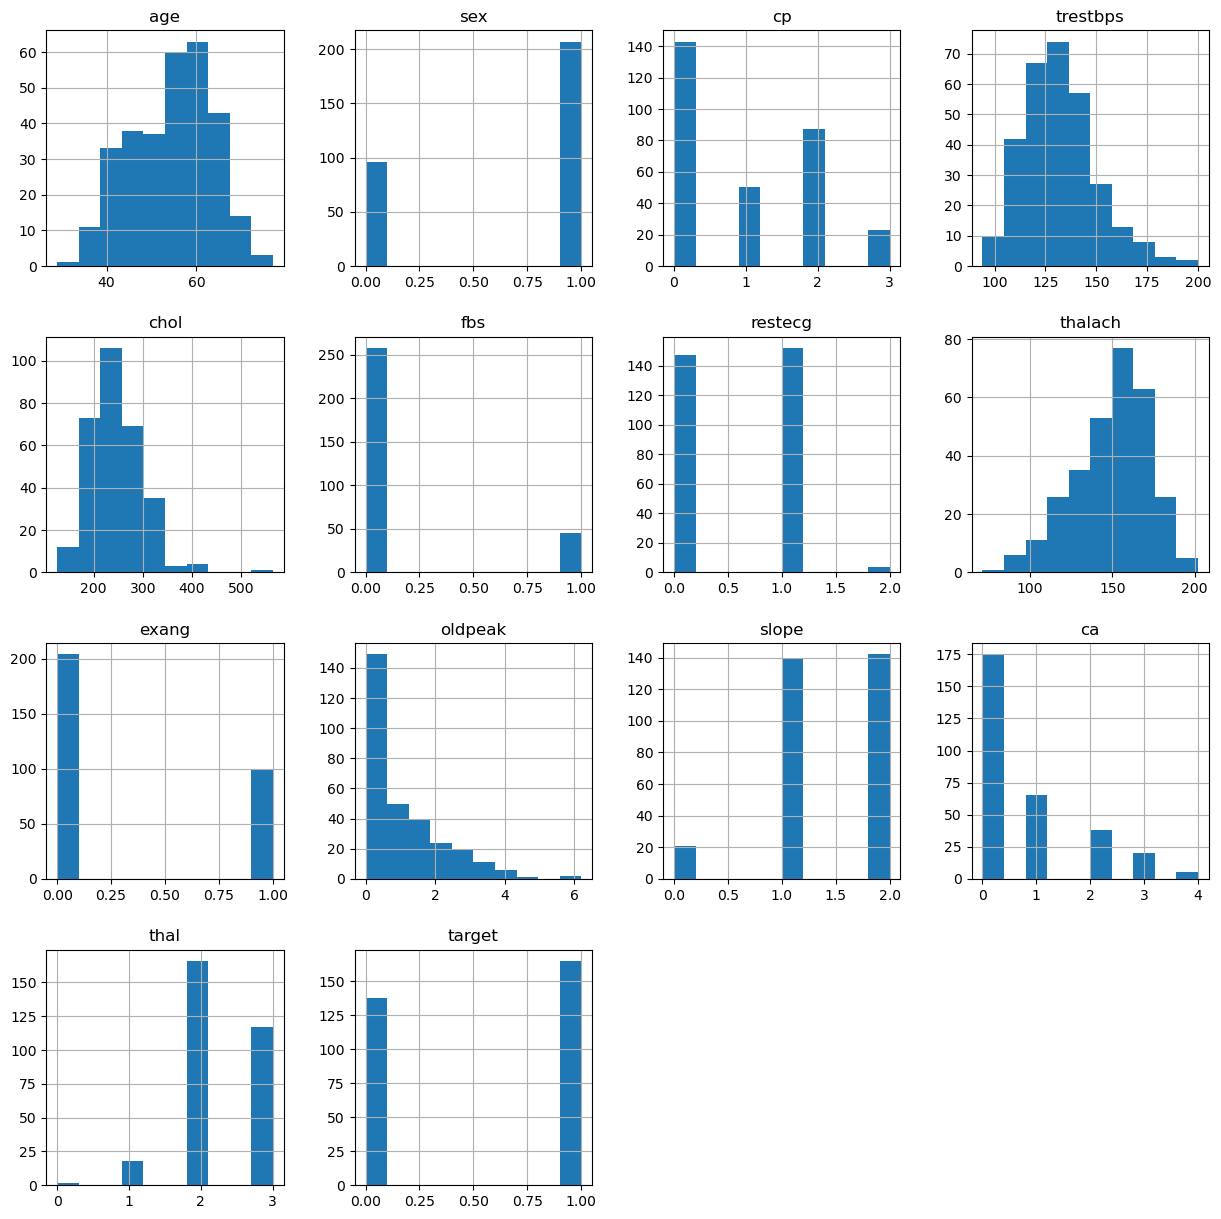

In [12]:
#plotting the graph for entire datasets
fig = plt.figure(figsize=(15,15))
ax = fig.gca()
g = df.hist(ax=ax)

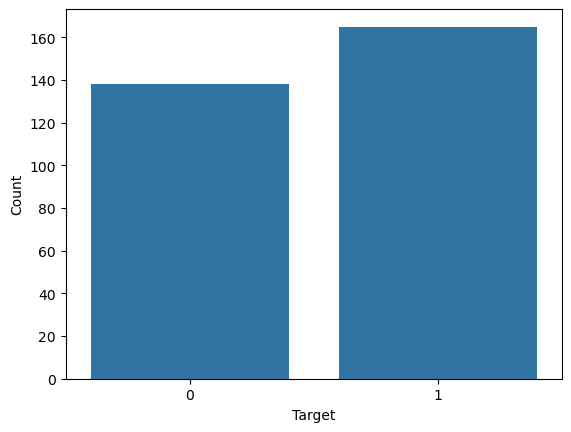

In [16]:
#graph to check if dataset is balanced
g = sns.countplot(x='target', data=df)
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

Feature Selection (Feature Engineering)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


<Axes: >

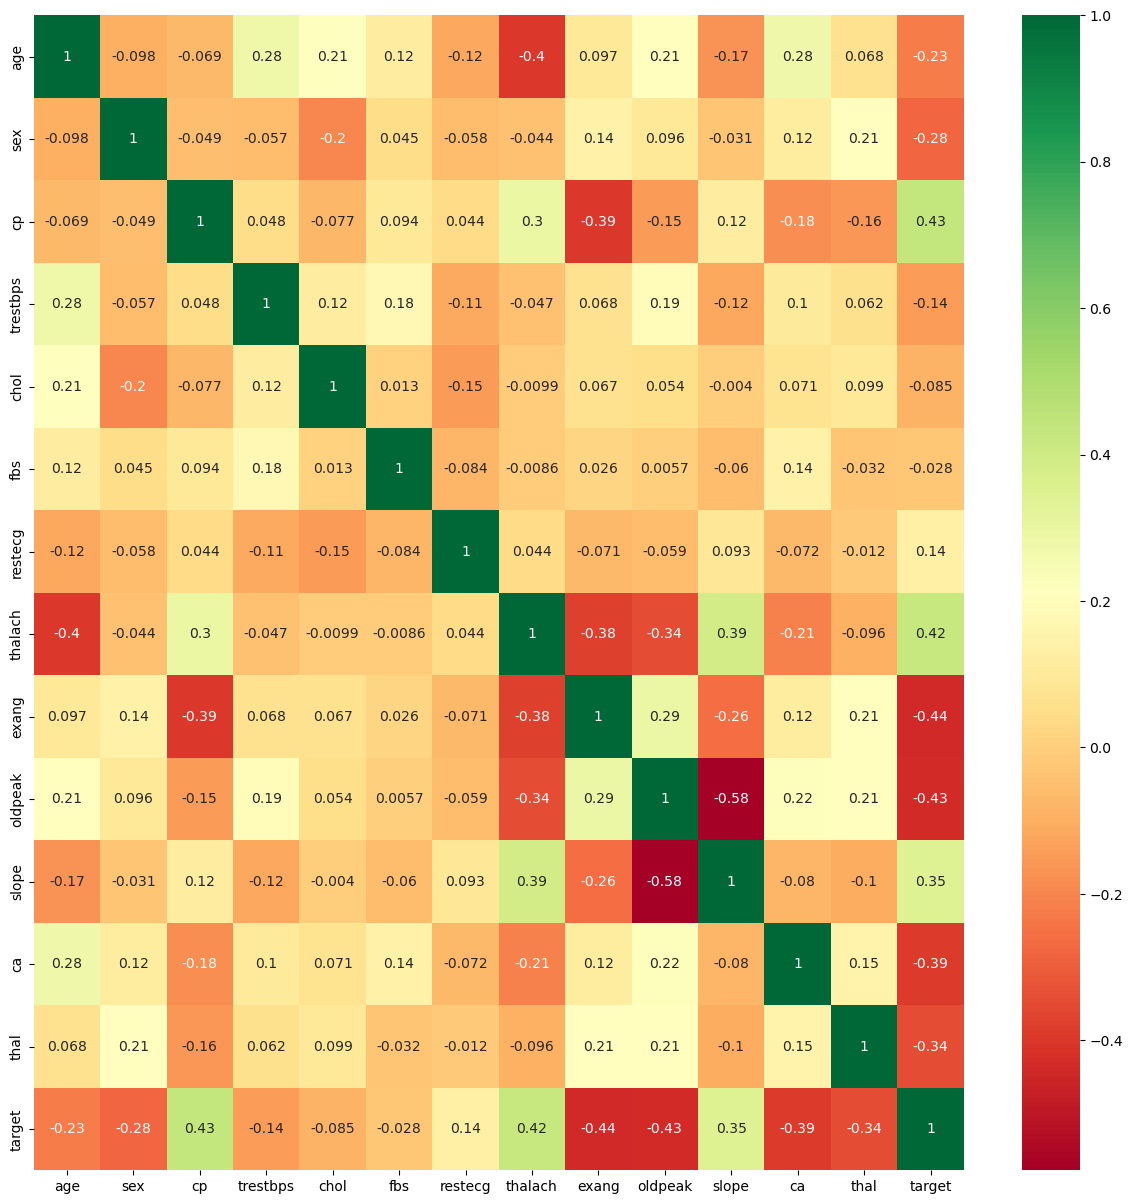

In [18]:
#get all correlation of all features of the datasets/
corr_matrix = df.corr()
top_corr_features = corr_matrix.index
print(top_corr_features)

#plotting the heatmap
plt.figure(figsize=(15,15))
sns.heatmap(data = df[top_corr_features].corr(), annot=True,cmap='RdYlGn')

Data Pre-processing

lets convert categorical variables into dummy variables by using get_dummies()

In [19]:
dataset = pd.get_dummies(df,columns=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'])

In [20]:
dataset.head()

,age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_2,ca_0,ca_1,ca_2,ca_3,ca_4,thal_0,thal_1,thal_2,thal_3
0,63,145,233,150,2.3,1,False,True,False,False,...,False,True,False,False,False,False,False,True,False,False
1,37,130,250,187,3.5,1,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
2,41,130,204,172,1.4,1,True,False,False,True,...,True,True,False,False,False,False,False,False,True,False
3,56,120,236,178,0.8,1,False,True,False,True,...,True,True,False,False,False,False,False,False,True,False
4,57,120,354,163,0.6,1,True,False,True,False,...,True,True,False,False,False,False,False,False,True,False


Feature Scaling:

In [21]:
from sklearn.preprocessing import StandardScaler
standScalar = StandardScaler()
cols_to_scale = ['age','trestbps','chol','thalach','oldpeak']
dataset[cols_to_scale] = standScalar.fit_transform(dataset[cols_to_scale])

In [23]:
all_features = dataset.drop('target',axis=1)
targets = dataset['target']

Splitting the data into train test split

In [27]:
from sklearn.model_selection import train_test_split, cross_val_score

x_train, x_test, y_train, y_test = train_test_split(all_features,targets,test_size=0.2)

Model Building:

1. KNeighbours Classifier
2. Decision Tree Classifier
3. Random Forest Classifier

KNeighbours Classifier

Text(0.5, 1.0, 'K Neighbors Classifier scores for different K values')

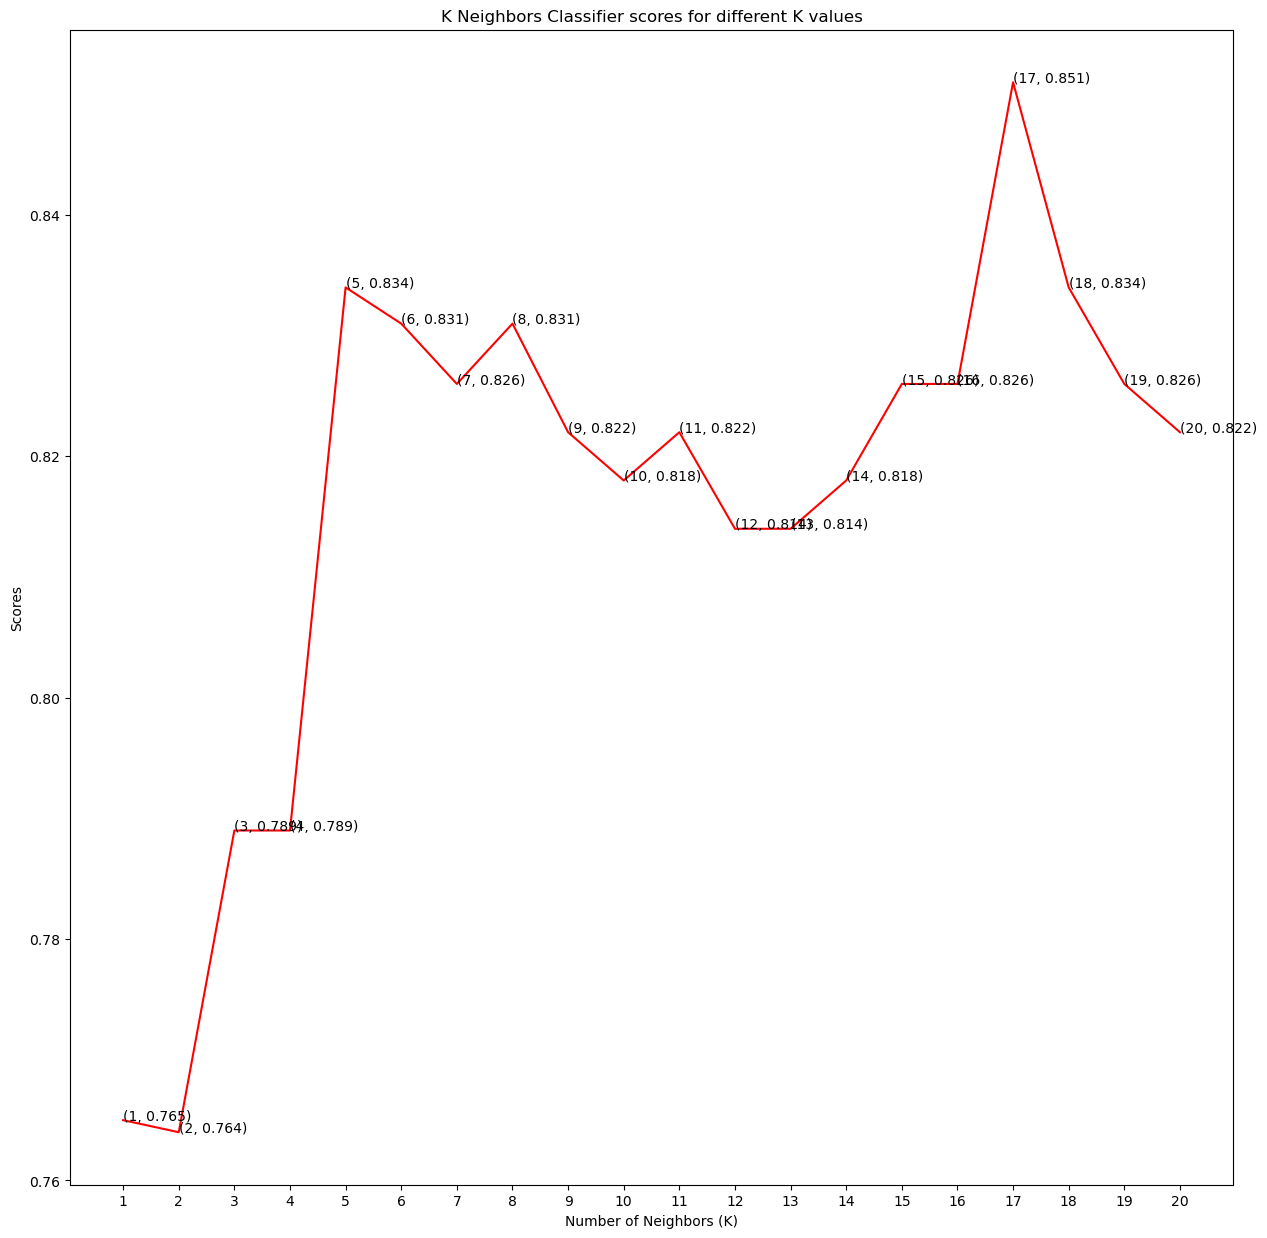

In [30]:
#importing essential modules:
from sklearn.neighbors import KNeighborsClassifier

#finding the best accuracy for the knn algorithm using cross_val_score
knn_scores = []
for i in range (1,21):
    knn_clf = KNeighborsClassifier(n_neighbors=i)
    cvs_scores = cross_val_score(knn_clf,x_train,y_train,cv=10)
    knn_scores.append(round(cvs_scores.mean(),3))

#plotting the results of the knnscores:
plt.figure(figsize=(15,15))
plt.plot([k for k in range(1,21)], knn_scores, color='red')
for i in range(1,21):
    plt.text(i, knn_scores[i-1], (i, knn_scores[i-1]))
plt.xticks([i for i in range(1, 21)])
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Scores')
plt.title('K Neighbors Classifier scores for different K values')

In [33]:
# Since N = 17 gave the highest accuracy:
knn_class = KNeighborsClassifier(n_neighbors=17)
cvs_scores = cross_val_score(knn_class,x_train,y_train,cv=10)
print('Accuracy: ',round(cvs_scores.mean(),3))

from sklearn.metrics import accuracy_score

knn_class.fit(x_train,y_train)
y_pred = knn_class.predict(x_test)
print ("Test Accuracy: ", accuracy_score(y_test,y_pred))

Accuracy:  0.851
Test Accuracy:  0.8360655737704918


Decision Trees:

Text(0.5, 1.0, 'Decision Tree Classifier scores for different depth values')

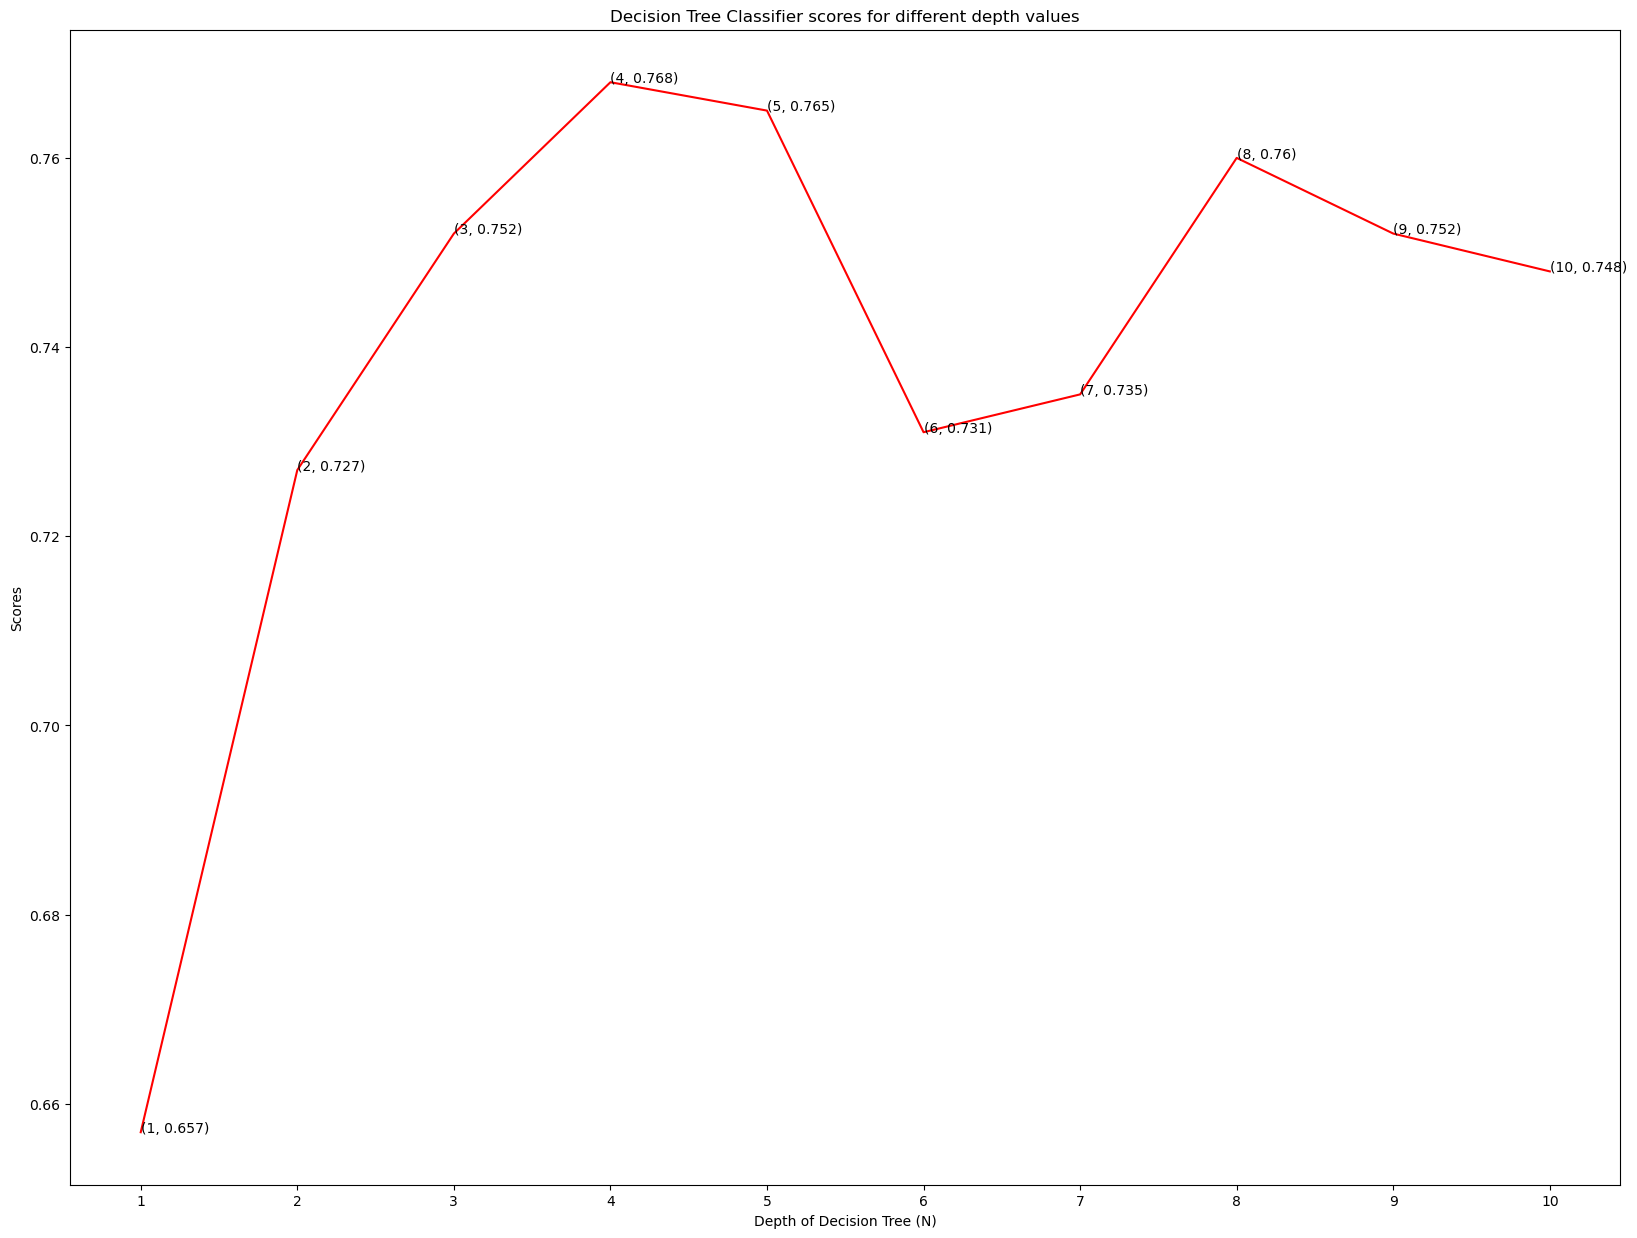

In [34]:
#importing modules
from sklearn.tree import DecisionTreeClassifier

decision_scores=[]

for i in range(1,11):
    clf = DecisionTreeClassifier(max_depth=i)
    cvs = cross_val_score(clf,x_train,y_train,cv=10)
    decision_scores.append(round(cvs.mean(),3))

#plotting
plt.figure(figsize=(20,15))
plt.plot([i for i in range(1, 11)], decision_scores, color = 'red')
for i in range(1,11):
    plt.text(i, decision_scores[i-1], (i, decision_scores[i-1]))
plt.xticks([i for i in range(1, 11)])
plt.xlabel('Depth of Decision Tree (N)')
plt.ylabel('Scores')
plt.title('Decision Tree Classifier scores for different depth values')

In [36]:
# Since max_depth = 4 gave the highest accuracy:
clf = DecisionTreeClassifier(max_depth=4)
cvs = cross_val_score(clf,x_train,y_train,cv=10)
print('Accuracy: ', round(cvs.mean(),3))

from sklearn.metrics import accuracy_score
clf.fit(x_train,y_train)
y_pred = clf.predict(x_test)
print('Test accuracy: ', accuracy_score(y_test,y_pred))

Accuracy:  0.764
Test accuracy:  0.7213114754098361


Random Forest Classifier

Text(0.5, 1.0, 'Random Forest Classifier scores for different N values')

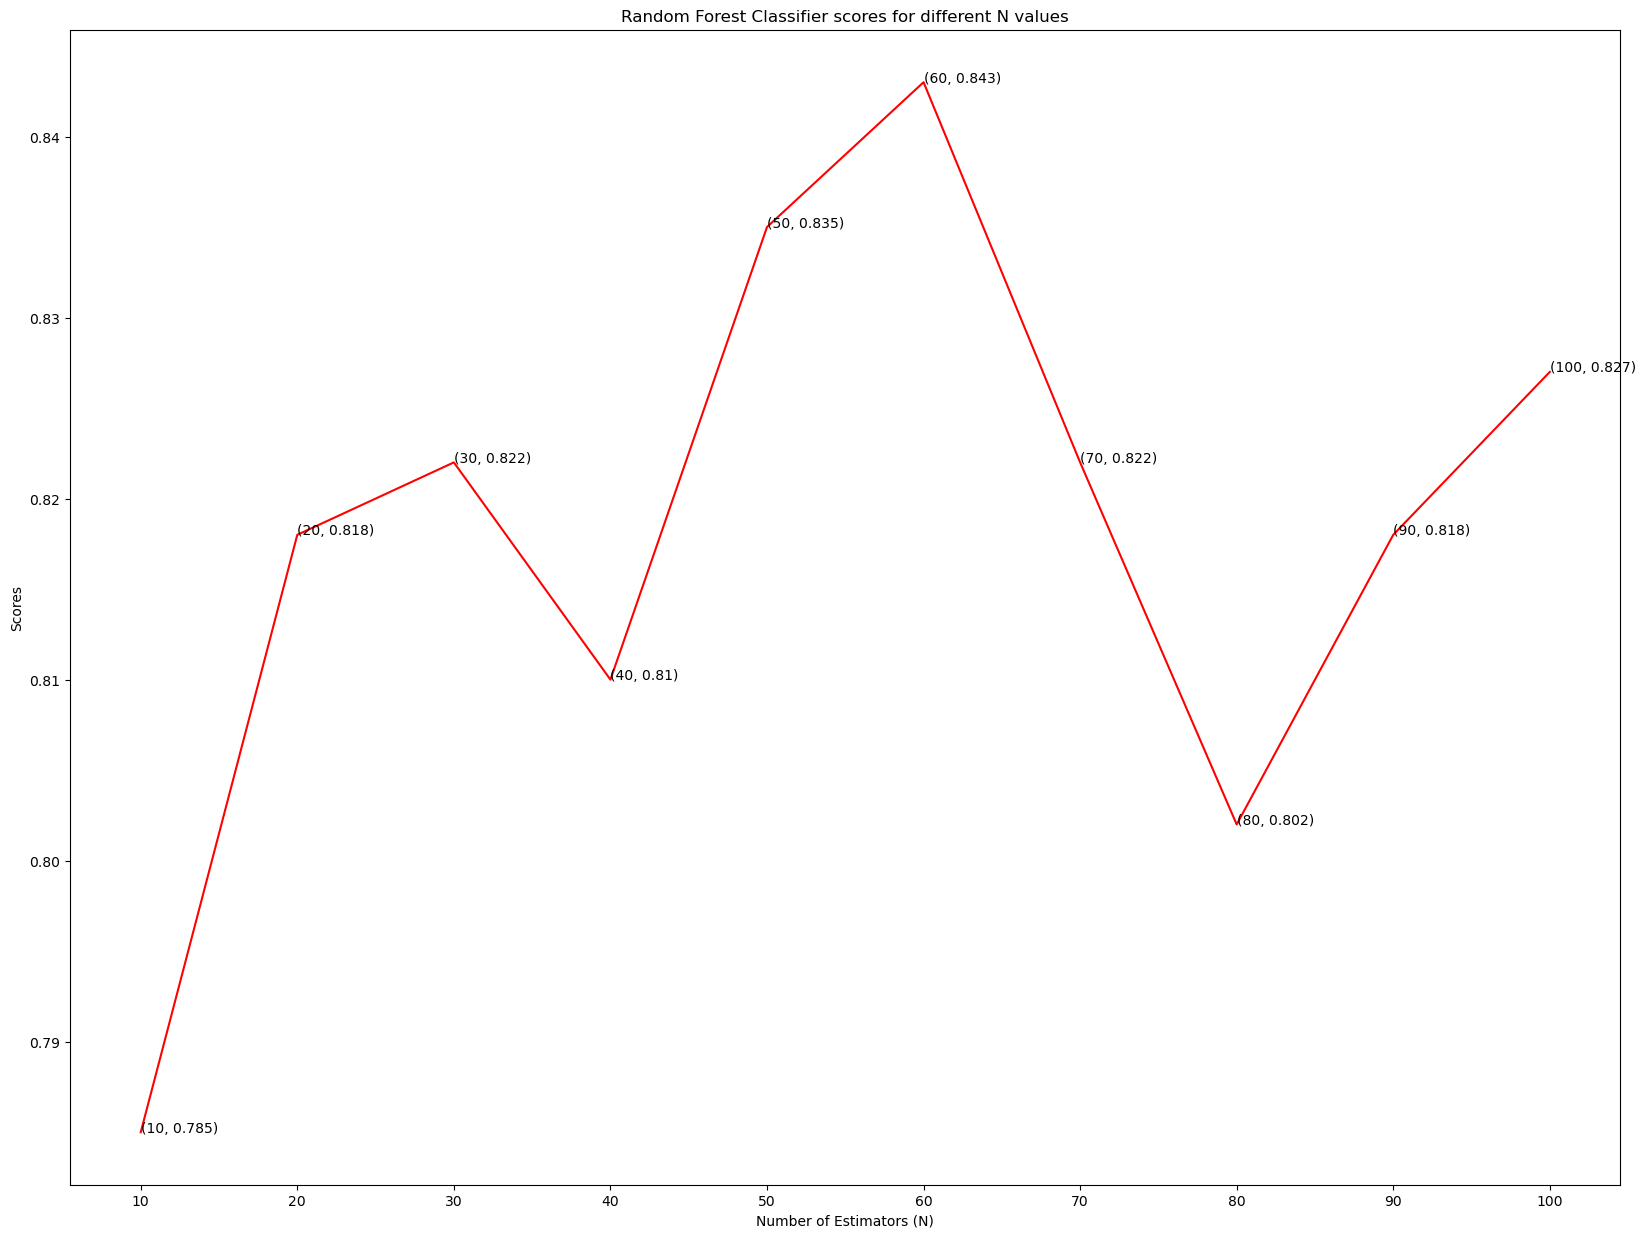

In [38]:
#importing modules
from sklearn.ensemble import RandomForestClassifier

#finding best accuracy 
rf_scores =[]

for i in range(10,101,10):
    clf_rf = RandomForestClassifier(n_estimators=i)
    cvs = cross_val_score(clf_rf,x_train,y_train,cv=5)
    rf_scores.append(round(cvs.mean(),3))

#plotting:
plt.figure(figsize=(20,15))
plt.plot([n for n in range(10, 101, 10)], rf_scores, color = 'red')
for i in range(1,11):
    plt.text(i*10, rf_scores[i-1], (i*10, rf_scores[i-1]))
plt.xticks([i for i in range(10, 101, 10)])
plt.xlabel('Number of Estimators (N)')
plt.ylabel('Scores')
plt.title('Random Forest Classifier scores for different N values')

In [40]:
#highest score for n_estimator = 60
clf_rf = RandomForestClassifier(n_estimators=60)
cvs = cross_val_score(clf_rf,x_train,y_train,cv=5)
print('Accuracy: ',round(cvs.mean(),3))

from sklearn.metrics import accuracy_score

clf_rf.fit(x_train,y_train)
y_pred = clf_rf.predict(x_test)
print('Test Accuracy: ', accuracy_score(y_test,y_pred))

Accuracy:  0.818
Test Accuracy:  0.8360655737704918
